#### 이진 분류
: Banknote Authentication Dataset - 진짜 지폐와 가짜 지폐 판별

- 데이터 : 1372개
- 정답 : 0 -> 진짜 | 1 -> 가짜
- 입력특징 : 4개
    - Variance(분산)
    - Skewness(왜도) : 좌우 어느 방향으로 치우쳐져 있는지
    - Curtosis(첨도) : 분포의 뾰족한 정도
    - Entropy(엔트로피) : 낮으면 특정 값이나 패턴에 집중되어 있다는 의미(높으면 다양하고 복잡한 분포 경향을 보임)
- 4개의 특징값(입력값)을 사용하여 결과(지폐의 진위여부)를 예측

In [8]:
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn, optim
import matplotlib.pyplot as plt
import numpy as np
import random

#### step 1. 데이터 불러오기 및 전처리

In [ ]:
columns = ['variance', 'skewness', 'curtosis', 'entropy', 'class']
df = pd.read_csv('data_banknote_authentication.txt', names=columns)
print(df.head())
print('데이터의 크기 :', df.shape)
print('클래스별 데이터 개수 :')
print(df['class'].value_counts().sort_index())

   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0
데이터의 크기 : (1372, 5)
클래스별 데이터 개수 :
class
0    762
1    610
Name: count, dtype: int64


In [10]:
# 입력 데이터(x)와 정답 데이터(y) 분리
x = torch.tensor(df[['variance', 'skewness', 'curtosis','entropy']].values, dtype=torch.float32)

y = torch.tensor(df['class'].values, dtype=torch.float32).reshape(-1,1)

# 클래스 별로 학습/테스트 데이터를 나누기
torch.manual_seed(42)
train_indices  =[]
test_indices =[]

# for class_value in [0,1] :
#     class_indices = []
#     for i in range(len(y)):
#         if y[i].item() == class_value:
#             class_indices.append(i)
    
#     # 순서를 무작위로
#     random.shuffle(class_indices)

#     # 학습 80%, 테스트 20% 분리
#     split = int(len(class_indices) * 0.8)

#     train_indices.extend(class_indices[:split])
#     test_indices.extend(class_indices[split:])

for class_value in [0,1]:
    #where() : 조건을 만족하는 데이터 찾기. 튜플로 반환
    class_indices = torch.where(y.squeeze() == class_value)[0]
    # randperm() : 0부터 지정한 숫자까지의 정수를 무작위로 섞어서 반환
    class_indices = class_indices[torch.randperm(len(class_indices))]
    # 학습 80%, 테스트 20% 분리
    split = int(len(class_indices) * 0.8)

    train_indices.extend(class_indices[:split])
    test_indices.extend(class_indices[split:])

# 학습/테스트 데이터 섞기(클래스 0은 앞쪽, 1은 뒷쪽에 몰려있음)
train_indices = torch.tensor(train_indices)[torch.randperm(len(train_indices))]
test_indices = torch.tensor(test_indices)[torch.randperm(len(test_indices))]

x_train = x[train_indices] # (1097,4)
x_test = x[test_indices] # (275,4)
y_train = y[train_indices] # (1097,1)
y_test = y[test_indices] # (275,1)

# 데이터 정규화: 데이터끼리의 편차가 클 때 평균0, 표준편차가 1이되도록 변환하는 작업
mean = x_train.mean(dim=0) #행의 방향, 즉 열의 평균
std = x_train.std(dim=0).clamp(min=1e-8)

x_train = (x_train-mean)/std
x_test = (x_test-mean)/std



In [11]:
# DataLoader 샏성
BATCH_SIZE = 32

train_DS = TensorDataset(x_train, y_train)
test_DS = TensorDataset(x_test,y_test)

train_DL = DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=False)

N = len(train_DL.dataset)
print(N)

1097


#### step 2. 모델 만들기

In [12]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear = nn.Sequential(nn.Linear(4,100),
                                    nn.Sigmoid(),
                                    nn.Linear(100,1),
                                    nn.Sigmoid()
                                    )

    def forward(self, x):
        x = self.linear(x)
        return x

model = MLP()

#### step 3. 모델 학습 시키기

In [13]:
LR = 1e-1
EPOCH = 100

optimizer = optim.SGD(model.parameters(), lr=LR)
criterion = nn.BCELoss()

loss_history = []

model.train()
for ep in range(EPOCH):
    rloss = 0

    for x_batch, y_batch in train_DL:
        #inference
        y_hat = model(x_batch)

        #loss
        loss = criterion(y_hat, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        rloss += loss.item() * x_batch.shape[0]

    epoch_loss = rloss / N
    loss_history.append(epoch_loss)

    print(f'Epoch : {ep+1} | loss : {epoch_loss:.4f}')
    print('-'*20)

Epoch : 1 | loss : 0.5965
--------------------
Epoch : 2 | loss : 0.4542
--------------------
Epoch : 3 | loss : 0.3698
--------------------
Epoch : 4 | loss : 0.3095
--------------------
Epoch : 5 | loss : 0.2634
--------------------
Epoch : 6 | loss : 0.2288
--------------------
Epoch : 7 | loss : 0.2007
--------------------
Epoch : 8 | loss : 0.1779
--------------------
Epoch : 9 | loss : 0.1586
--------------------
Epoch : 10 | loss : 0.1439
--------------------
Epoch : 11 | loss : 0.1312
--------------------
Epoch : 12 | loss : 0.1207
--------------------
Epoch : 13 | loss : 0.1124
--------------------
Epoch : 14 | loss : 0.1049
--------------------
Epoch : 15 | loss : 0.0985
--------------------
Epoch : 16 | loss : 0.0929
--------------------
Epoch : 17 | loss : 0.0884
--------------------
Epoch : 18 | loss : 0.0835
--------------------
Epoch : 19 | loss : 0.0803
--------------------
Epoch : 20 | loss : 0.0773
--------------------
Epoch : 21 | loss : 0.0737
--------------------
E

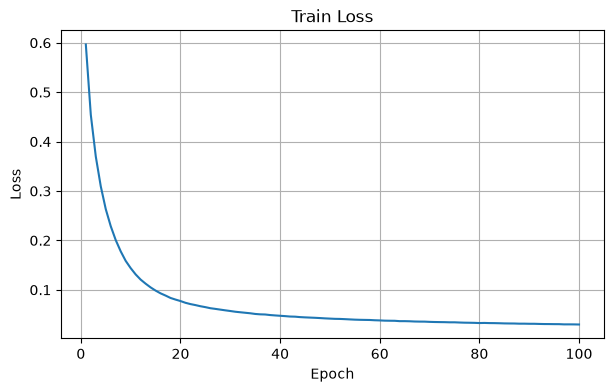

In [14]:
plt.figure(figsize=(7,4))
plt.plot(range(1,EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Train Loss')
plt.grid()

In [15]:
model.eval()

correct = 0
total = 0
with torch.no_grad():
    for x_batch, y_batch in test_DL:
        y_hat = model(x_batch)
        pred = (y_hat >= 0.5).float()

        correct += (pred == y_batch).sum().item()
        total += y_batch.numel()

accuracy = correct / total * 100
print(f'Test accuracy : {correct}/{total}({accuracy:.1f})')

Test accuracy : 269/275(97.8)


#### step 5. 테스트 결과 시각화

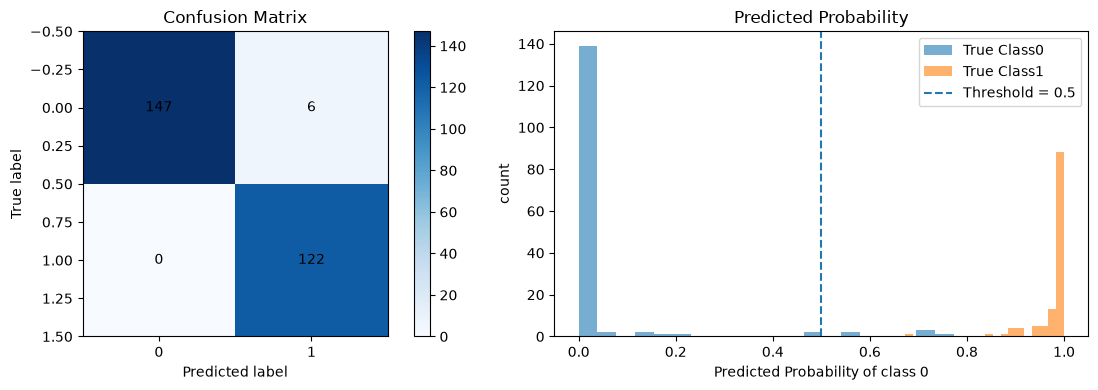

In [24]:
model.eval()

y_true_all = [] #정답 전체
y_prob_all = [] #예측값 전체

with torch.no_grad():
    for x_batch, y_batch in test_DL:
        y_hat = model(x_batch)

        y_true_all.append(y_batch.numpy().reshape(-1))
        y_prob_all.append(y_hat.numpy().reshape(-1))

# 배치별로 나누어 저장한 실제 정답 배열을 하나로 결함 후 데이터 타입을 정수형으로 변환
y_true = np.concatenate(y_true_all).astype(int)
y_prob = np.concatenate(y_prob_all)
y_pred = (y_prob >= 0.5).astype(int)

#혼동행렬 : 행은 실제 클래스, 열은 예측 클래스
cm = np.zeros((2,2),dtype=int)
for true, pred in zip(y_true, y_pred):
    cm[true, pred] += 1

fig, axes = plt.subplots(1,2, figsize=(12,4))

im = axes[0].imshow(cm, cmap='Blues')
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted label')
axes[0].set_ylabel('True label')
axes[0].set_xticks([0,1], labels=['0','1'])

for i in range(2):
    for j in range(2):
        axes[0].text(j,i, cm[i,j], ha='center', va='center')

fig.colorbar(im, ax=axes[0])

# 클래스별 예측 확률 분포

axes[1].hist(y_prob[y_true == 0], bins=20, alpha=0.6, label='True Class0')
axes[1].hist(y_prob[y_true == 1], bins=20, alpha=0.6, label='True Class1')

axes[1].axvline(0.5, linestyle='--', label='Threshold = 0.5')
axes[1].set_title('Predicted Probability')
axes[1].set_xlabel('Predicted Probability of class 0')
axes[1].set_ylabel('count')
axes[1].legend()

plt.tight_layout()

plt.show()